# DPE — Contrôle de 1 000 diagnostics

Vérification des champs, des valeurs manquantes et des cibles sur 1 000 maisons
de la région 84, issues de la première page de l'API ADEME.
Ce prélèvement non aléatoire sert à examiner les données ; le fichier utilisé
pour les modèles contient 80 000 diagnostics dans `notebook.ipynb`.

Source : https://data.ademe.fr/datasets/dpe03existant

Exécution : ouvrir ce notebook à la racine du dépôt avec `data/pilot/`.
Dans Colab, transférer aussi ce dossier en gardant la même structure.

## 1. Imports, chemins et version des données
L'empreinte SHA-256 identifie la copie du fichier utilisée.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "pilot"
REPORT = ROOT / "reports" / "pilot"
REPORT.mkdir(parents=True, exist_ok=True)
path = DATA / "dpe_region84_pilot_1000.csv.gz"
manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest["sha256"]
print("Téléchargement UTC :", manifest["retrieved_at_utc"])
print("Filtre :", manifest["query"])
print("Sélection :", manifest["selection"])
print("pandas :", pd.__version__)

Téléchargement UTC : 2026-11-15T12:22:34.998483+00:00
Filtre : type_batiment:maison AND code_region_ban:84
Sélection : First API page in default order; not random or representative.
pandas : 2.2.2


## 2. Charger le fichier et regarder quelques lignes
Une ligne correspond à un diagnostic, pas nécessairement à un bâtiment unique.
Les 38 colonnes comprennent 24 entrées candidates, 4 sorties ou cibles,
8 champs administratifs et 2 champs de contrôle.

In [2]:
df = pd.read_csv(path, dtype={
    "numero_dpe": "string", "numero_dpe_remplace": "string",
    "code_insee_ban": "string", "code_departement_ban": "string",
    "code_region_ban": "string", "id_rnb": "string",
})
print("Lignes, colonnes :", df.shape)
assert len(df) == 1000
assert df["type_batiment"].eq("maison").all()
assert df["code_region_ban"].eq("84").all()
display(df[["surface_habitable_logement", "periode_construction",
    "type_energie_principale_chauffage", "conso_5_usages_par_m2_ep", "etiquette_dpe"]].head())

Lignes, colonnes : (1000, 38)


,surface_habitable_logement,periode_construction,type_energie_principale_chauffage,conso_5_usages_par_m2_ep,etiquette_dpe
0,103.0,avant 1948,Électricité,285.0,E
1,35.9,1989-2000,Gaz naturel,238.1,D
2,171.7,1983-1988,Gaz naturel,185.0,D
3,75.8,1978-1982,Électricité,267.2,E
4,69.0,1948-1974,Électricité,116.0,C


## 3. Types et valeurs manquantes
Taux de remplissage des 24 entrées candidates.
Une absence peut signifier « inconnu » ou « non applicable » ; elle ne correspond
pas forcément à zéro.

In [3]:
df.info()
features = manifest["candidate_features"]
quality = pd.DataFrame({
    "Type lu": df[features].dtypes.astype(str),
    "Manquants": df[features].isna().sum(),
    "Manquants (%)": (100 * df[features].isna().mean()).round(1),
    "Valeurs distinctes": df[features].nunique(),
}).sort_values("Manquants (%)", ascending=False)
display(quality)
print("Lignes restantes si on appliquait dropna() à toutes les colonnes :", len(df.dropna()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   numero_dpe                                      1000 non-null   string 
 1   numero_dpe_remplace                             125 non-null    string 
 2   date_etablissement_dpe                          1000 non-null   object 
 3   code_insee_ban                                  1000 non-null   string 
 4   code_departement_ban                            1000 non-null   string 
 5   code_region_ban                                 1000 non-null   string 
 6   coordonnee_cartographique_x_ban                 1000 non-null   float64
 7   coordonnee_cartographique_y_ban                 1000 non-null   float64
 8   surface_habitable_logement                      1000 non-null   float64
 9   annee_construction                        

,Type lu,Manquants,Manquants (%),Valeurs distinctes
type_installation_chauffage,float64,1000,100.0,0
qualite_isolation_plancher_haut_toit_terrasse,object,867,86.7,4
surface_totale_capteurs_pv,float64,849,84.9,53
type_ventilation,object,809,80.9,19
presence_production_pv,float64,789,78.9,2
qualite_isolation_plancher_haut_comble_amenage,object,689,68.9,4
annee_construction,float64,564,56.4,86
qualite_isolation_plancher_haut_comble_perdu,object,416,41.6,4
type_generateur_chauffage_principal,object,258,25.8,70
isolation_toiture,float64,31,3.1,2


Lignes restantes si on appliquait dropna() à toutes les colonnes : 0


## 4. Examiner quelques catégories
Catégories présentes et fréquences dans les 1 000 diagnostics.

In [4]:
for column in ["periode_construction", "type_energie_principale_chauffage", "type_ventilation"]:
    print("\n", column)
    display(df[column].fillna("<MANQUANT>").value_counts().head(12).to_frame("Effectif"))


 periode_construction


,Effectif
periode_construction,
avant 1948,352
1948-1974,185
1989-2000,100
2006-2012,75
1983-1988,67
1978-1982,67
2013-2021,54
2001-2005,49
1975-1977,28



 type_energie_principale_chauffage


,Effectif
type_energie_principale_chauffage,
Électricité,520
Gaz naturel,216
Fioul domestique,123
Bois – Bûches,86
Bois – Granulés (pellets) ou briquettes,39
GPL,12
Propane,2
Bois – Plaquettes d’industrie,1
Réseau de Chauffage urbain,1



 type_ventilation


,Effectif
type_ventilation,
<MANQUANT>,809
VMC SF Auto réglable de 2001 à 2012,30
Ventilation par ouverture des fenêtres,26
VMC SF Auto réglable après 2012,26
VMC SF Auto réglable de 1982 à 2000,24
VMC SF Auto réglable avant 1982,19
VMC SF Hygro B après 2012,17
VMC SF Hygro A après 2012,11
Ventilation par entrées d'air hautes et basses,8


## 5. Vérifier les deux cibles et les valeurs numériques
Les consommations, étiquettes et émissions sont exclues des entrées du modèle
pour éviter la fuite de données. La consommation DPE est calculée,
pas mesurée au compteur.

In [5]:
target = pd.to_numeric(df["conso_5_usages_par_m2_ep"], errors="coerce")
area = pd.to_numeric(df["surface_habitable_logement"], errors="coerce")
display(df[["surface_habitable_logement", "hauteur_sous_plafond",
    "nombre_niveau_logement", "conso_5_usages_par_m2_ep"]].describe())
print("Cible régression manquante :", target.isna().sum())
print("Consommation négative :", target.lt(0).sum())
print("Surface non positive :", area.le(0).sum())
print("Étiquettes absentes ou hors A–G :", (~df["etiquette_dpe"].isin(list("ABCDEFG"))).sum())
display(df["etiquette_dpe"].value_counts().reindex(list("ABCDEFG"), fill_value=0).to_frame("Effectif"))

,surface_habitable_logement,hauteur_sous_plafond,nombre_niveau_logement,conso_5_usages_par_m2_ep
count,1000.000000,1000.00000,1000.000000,1000.000000
mean,120.322200,2.52340,1.878000,231.577800
std,58.383515,0.15025,0.689631,127.307259
min,21.600000,2.00000,1.000000,38.000000
25%,82.975000,2.50000,1.000000,142.375000
50%,105.250000,2.50000,2.000000,207.000000
75%,144.450000,2.50000,2.000000,294.000000
max,623.200000,3.80000,4.000000,1098.000000


Cible régression manquante : 0
Consommation négative : 0
Surface non positive : 0
Étiquettes absentes ou hors A–G : 0


,Effectif
etiquette_dpe,
A,37
B,72
C,254
D,273
E,180
F,97
G,87


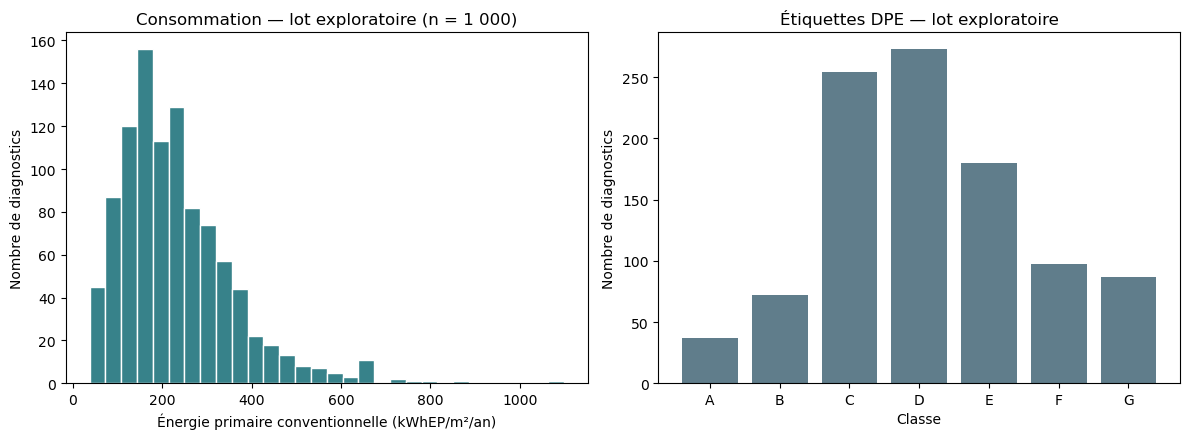

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(target.dropna(), bins=30, color="#37828a", edgecolor="white")
axes[0].set(title="Consommation — lot exploratoire (n = 1 000)",
    xlabel="Énergie primaire conventionnelle (kWhEP/m²/an)", ylabel="Nombre de diagnostics")
counts = df["etiquette_dpe"].value_counts().reindex(list("ABCDEFG"), fill_value=0)
axes[1].bar(counts.index, counts.values, color="#607d8b")
axes[1].set(title="Étiquettes DPE — lot exploratoire", xlabel="Classe", ylabel="Nombre de diagnostics")
fig.tight_layout()
fig.savefig(REPORT / "pilot_overview.png", dpi=150)
plt.show()

## 6. Dates et diagnostics liés à un bâtiment
Répartition par date et recherche de diagnostics partageant un identifiant RNB.
Des numéros DPE différents peuvent concerner le même bâtiment.

In [7]:
dates = pd.to_datetime(df["date_etablissement_dpe"], errors="coerce")
print("Dates :", dates.min().date(), "→", dates.max().date())
display(dates.dt.year.value_counts().sort_index().to_frame("Diagnostics"))
print("Numéros DPE répétés au-delà de la première occurrence :", df["numero_dpe"].dropna().duplicated().sum())
rnb = df["id_rnb"].replace(r"^\s*$", pd.NA, regex=True)
print("Identifiant RNB manquant :", rnb.isna().sum())
print("Identifiants RNB distincts renseignés :", rnb.nunique())
print("Occurrences RNB répétées au-delà de la première :", rnb.dropna().duplicated().sum())
print("Groupes RNB comportant plusieurs diagnostics :", rnb.value_counts().gt(1).sum())

Dates : 2021-09-24 → 2026-01-12


,Diagnostics
date_etablissement_dpe,
2021,35
2022,8
2023,17
2024,37
2025,95
2026,808


Numéros DPE répétés au-delà de la première occurrence : 0
Identifiant RNB manquant : 659
Identifiants RNB distincts renseignés : 330
Occurrences RNB répétées au-delà de la première : 11
Groupes RNB comportant plusieurs diagnostics : 9


## 7. Résultats du contrôle

- Les deux cibles sont renseignées et les classes A–G sont présentes.
- L'année exacte de construction manque souvent, contrairement à la période.
- `type_installation_chauffage` est vide. Le champ
  `type_installation_chauffage_n1` du schéma officiel est une autre piste.
- Les absences pour la ventilation, la toiture et le photovoltaïque
  ne suffisent pas à conclure à l'absence d'équipement.
- Plusieurs diagnostics partagent un RNB ; beaucoup n'en ont pas.

Ces résultats concernent seulement les 1 000 diagnostics examinés.
L'analyse du fichier de 80 000 lignes se trouve dans `notebook.ipynb`.